# Model Comparison

This notebook compares the results produced by the six baseline experiments and the advanced DAVIS experiment.

The notebook does **not train any model**. It reads the saved metrics files from `results/metrics/` and produces consistent comparison tables and figures.

The comparisons are kept scientifically separate:

- DAVIS baseline models: GCN + CNN, GAT + CNN, and GIN + CNN
- KIBA baseline models: GCN + CNN, GAT + CNN, and GIN + CNN
- DAVIS baselines versus the advanced GINE + frozen ESM-2 model

DAVIS and KIBA RMSE values are **not directly compared with each other** because the two datasets use different affinity target scales.

## Notebook workflow

```text
Saved metrics from model notebooks
        │
        ├── DAVIS GCN + CNN
        ├── DAVIS GAT + CNN
        ├── DAVIS GIN + CNN
        ├── KIBA GCN + CNN
        ├── KIBA GAT + CNN
        ├── KIBA GIN + CNN
        └── DAVIS Advanced GINE + ESM-2
        │
        ▼
Validate result files and columns
        │
        ▼
Combine all metrics into one table
        │
        ├─────────────────────────────┐
        ▼                             ▼
DAVIS comparisons                KIBA comparisons
        │                             │
        ▼                             ▼
Random / Cold-drug /            Random / Cold-drug /
Cold-target                     Cold-target
        │                             │
        └──────────────┬──────────────┘
                       ▼
              Rank models per split
                       │
                       ▼
         Compare DAVIS advanced model
             with DAVIS baselines
                       │
                       ▼
          Save comparison CSV files
              and summary figures
```

Lower MSE, RMSE, and MAE indicate better regression performance.  
Higher Concordance Index and Pearson correlation indicate better ranking and agreement.

In [1]:
# ============================================================
# COLAB SETUP — DRIVE + GITHUB + PERMANENT RESULTS
# ============================================================

from google.colab import drive, userdata
from pathlib import Path

import base64
import os
import shutil
import subprocess
import torch


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive", force_remount=False)


# ------------------------------------------------------------
# 2. Project settings
# ------------------------------------------------------------

GITHUB_REPO = "https://github.com/Thebluesky303/msc-dissertation-drug-repurposing.git"

BRANCH = "final-aml-gnn-dta"

REPO_DIR = Path("/content/final-msc-dissertation-drug-repurposing")

DRIVE_PROJECT = Path("/content/drive/MyDrive/final-msc-dissertation-drug-repurposing")

DRIVE_RESULTS = DRIVE_PROJECT / "results"


# ------------------------------------------------------------
# 3. Create permanent Drive folders
# ------------------------------------------------------------

result_folders = [
    "metrics",
    "predictions",
    "figures",
    "checkpoints",
    "esm_embeddings",
    "validation",
    "validation_cache",
]

DRIVE_PROJECT.mkdir(parents=True, exist_ok=True)
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)

for folder_name in result_folders:
    (DRIVE_RESULTS / folder_name).mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 4. Read GitHub token from Colab Secrets
# ------------------------------------------------------------

token = userdata.get("colab-dissertation")

if not token:
    raise ValueError("GITHUB_TOKEN was not found in Colab Secrets.")

auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
git_auth = f"AUTHORIZATION: basic {auth}"


# ------------------------------------------------------------
# 5. Clone repository if it does not exist
#    Otherwise update the existing clone
# ------------------------------------------------------------

if not (REPO_DIR / ".git").exists():
    print("Cloning repository...")

    subprocess.run(
        [
            "git",
            "-c", f"http.extraheader={git_auth}",
            "clone",
            "--branch", BRANCH,
            "--single-branch",
            GITHUB_REPO,
            str(REPO_DIR),
        ],
        check=True,
    )

else:
    print("Repository already exists.")

    subprocess.run(
        ["git", "-C", str(REPO_DIR), "-c", f"http.extraheader={git_auth}", "fetch", "origin", BRANCH],
        check=True,
    )

    subprocess.run(
        ["git", "-C", str(REPO_DIR), "switch", BRANCH],
        check=True,
    )

    subprocess.run(
        ["git", "-C", str(REPO_DIR), "-c", f"http.extraheader={git_auth}", "pull", "--ff-only", "origin", BRANCH],
        check=True,
    )


# ------------------------------------------------------------
# 6. Connect repo/results directly to Google Drive
# ------------------------------------------------------------

LOCAL_RESULTS = REPO_DIR / "results"

if LOCAL_RESULTS.is_symlink():
    current_target = LOCAL_RESULTS.resolve()

    if current_target != DRIVE_RESULTS.resolve():
        LOCAL_RESULTS.unlink()

elif LOCAL_RESULTS.exists():
    # Copy any existing local results before replacing
    # the folder with the Drive link.
    for item in LOCAL_RESULTS.iterdir():
        destination = DRIVE_RESULTS / item.name

        if item.is_dir():
            shutil.copytree(item, destination, dirs_exist_ok=True)
        else:
            shutil.copy2(item, destination)

    shutil.rmtree(LOCAL_RESULTS)


if not LOCAL_RESULTS.exists():
    os.symlink(DRIVE_RESULTS, LOCAL_RESULTS, target_is_directory=True)


# ------------------------------------------------------------
# 7. Move into repository
# ------------------------------------------------------------

os.chdir(REPO_DIR)


# ------------------------------------------------------------
# 8. Final checks
# ------------------------------------------------------------

branch = subprocess.check_output(["git", "branch", "--show-current"], text=True).strip()
commit = subprocess.check_output(["git", "log", "-1", "--oneline"], text=True).strip()

print()
print("=" * 65)
print("COLAB PROJECT READY")
print("=" * 65)

print("Repository:", REPO_DIR)
print("Branch:", branch)
print("Commit:", commit)
print("Results saved to Drive:", LOCAL_RESULTS.resolve())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("=" * 65)


# Install project dependencies for this Colab runtime

%cd /content/final-msc-dissertation-drug-repurposing

!pip install -q -r requirements.txt

print("Project requirements installed.")

import torch
import torch_geometric
import rdkit
import transformers
import pandas
import numpy

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Environment ready.")

Mounted at /content/drive
Cloning repository...

COLAB PROJECT READY
Repository: /content/final-msc-dissertation-drug-repurposing
Branch: final-aml-gnn-dta
Commit: 281b6ee gine esm-2 updated model trained.
Results saved to Drive: /content/drive/MyDrive/final-msc-dissertation-drug-repurposing/results
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB
/content
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 79.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 74.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 127.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 135.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 915.3/915.3 kB 55.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.8/59.8 kB 7.7 MB/s eta 0:00:00
Project req

# Part A — Setup

## 1. Imports

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

## 2. Locate the project folder

In [3]:
def find_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content/final_aml_gnn_dta"),
    ]

    content_dir = Path("/content")

    if content_dir.exists():
        candidates.extend(
            path.parent
            for path in content_dir.glob("*/config.py")
        )

    for candidate in candidates:
        if (
            (candidate / "config.py").exists()
            and (candidate / "results").exists()
        ):
            return candidate.resolve()

    raise FileNotFoundError(
        "Project root could not be found. "
        "Run this notebook from the final_aml_gnn_dta project."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /content/final-msc-dissertation-drug-repurposing


## 3. Project result folders

In [4]:
from config import (
    FIGURES_DIR,
    METRICS_DIR,
)

COMPARISON_DIR = METRICS_DIR / "comparisons"
COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Metrics folder:", METRICS_DIR)
print("Figures folder:", FIGURES_DIR)
print("Comparison folder:", COMPARISON_DIR)

Metrics folder: /content/final-msc-dissertation-drug-repurposing/results/metrics
Figures folder: /content/final-msc-dissertation-drug-repurposing/results/figures
Comparison folder: /content/final-msc-dissertation-drug-repurposing/results/metrics/comparisons


# Part B — Load and validate model results

## 4. Expected metrics files

Each model notebook should save one CSV file containing three rows: random, cold-drug, and cold-target.

The advanced DAVIS notebook follows the same format.

In [5]:
RESULT_FILES = {
    "davis_gcn": METRICS_DIR / "davis_gcn_cnn.csv",
    "davis_gat": METRICS_DIR / "davis_gat_cnn.csv",
    "davis_gin": METRICS_DIR / "davis_gin_cnn.csv",
    "kiba_gcn": METRICS_DIR / "kiba_gcn_cnn.csv",
    "kiba_gat": METRICS_DIR / "kiba_gat_cnn.csv",
    "kiba_gin": METRICS_DIR / "kiba_gin_cnn.csv",
    "davis_advanced": (
        METRICS_DIR
        / "davis_advanced_gine_esm2.csv"
    ),
}

file_check = pd.DataFrame(
    {
        "result": RESULT_FILES.keys(),
        "file": [
            path.name
            for path in RESULT_FILES.values()
        ],
        "exists": [
            path.exists()
            for path in RESULT_FILES.values()
        ],
    }
)

display(file_check)

missing_files = [
    path.name
    for path in RESULT_FILES.values()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following result files are missing. "
        "Run the corresponding model notebooks first: "
        + ", ".join(missing_files)
    )

,result,file,exists
0,davis_gcn,davis_gcn_cnn.csv,True
1,davis_gat,davis_gat_cnn.csv,True
2,davis_gin,davis_gin_cnn.csv,True
3,kiba_gcn,kiba_gcn_cnn.csv,True
4,kiba_gat,kiba_gat_cnn.csv,True
5,kiba_gin,kiba_gin_cnn.csv,True
6,davis_advanced,davis_advanced_gine_esm2.csv,True


## 5. Load and check the result tables

In [6]:
REQUIRED_COLUMNS = {
    "dataset",
    "model",
    "split",
    "best_epoch",
    "completed_epochs",
    "best_validation_mse",
    "test_mse",
    "test_rmse",
    "test_mae",
    "ci",
    "pearson",
    "trainable_parameters",
}


def load_result_file(file_path: Path) -> pd.DataFrame:
    result_df = pd.read_csv(file_path)

    missing_columns = (
        REQUIRED_COLUMNS
        .difference(result_df.columns)
    )

    if missing_columns:
        raise ValueError(
            f"{file_path.name} is missing columns: "
            f"{sorted(missing_columns)}"
        )

    expected_splits = {
        "random",
        "cold_drug",
        "cold_target",
    }

    found_splits = set(
        result_df["split"].astype(str)
    )

    if found_splits != expected_splits:
        raise ValueError(
            f"{file_path.name} must contain exactly "
            f"{sorted(expected_splits)}. "
            f"Found {sorted(found_splits)}."
        )

    return result_df.copy()


result_tables = [
    load_result_file(file_path)
    for file_path in RESULT_FILES.values()
]

all_results_df = pd.concat(
    result_tables,
    ignore_index=True,
)

print(
    "Combined result rows:",
    len(all_results_df),
)

display(
    all_results_df.head()
)

Combined result rows: 21


,dataset,model,split,best_epoch,completed_epochs,best_validation_mse,test_mse,test_rmse,test_mae,ci,pearson,trainable_parameters
0,DAVIS,GCN + CNN,random,143,163.0,0.261947,0.260653,0.510542,0.299281,0.877014,0.811508,384129
1,DAVIS,GCN + CNN,cold_drug,52,72.0,0.602026,0.639775,0.799859,0.485369,0.773581,0.530486,384129
2,DAVIS,GCN + CNN,cold_target,142,162.0,0.320287,0.446281,0.668043,0.389921,0.826476,0.755499,384129
3,DAVIS,GAT + CNN,random,93,113.0,0.332526,0.342147,0.584933,0.349543,0.844804,0.741747,384897
4,DAVIS,GAT + CNN,cold_drug,52,72.0,0.512712,0.475197,0.689345,0.431069,0.763880,0.555493,384897


## 6. Save the combined result table

In [7]:
all_results_path = (
    COMPARISON_DIR
    / "all_model_results.csv"
)

all_results_df.to_csv(
    all_results_path,
    index=False,
)

print(
    "Combined results saved to:",
    all_results_path,
)

Combined results saved to: /content/final-msc-dissertation-drug-repurposing/results/metrics/comparisons/all_model_results.csv


# Part C — DAVIS baseline comparison

## 7. DAVIS baseline results

This section compares only the three baseline drug encoders while keeping the protein CNN and prediction head consistent.

In [8]:
davis_baseline_df = all_results_df[
    (all_results_df["dataset"] == "DAVIS")
    & (
        all_results_df["model"].isin(
            [
                "GCN + CNN",
                "GAT + CNN",
                "GIN + CNN",
            ]
        )
    )
].copy()

davis_baseline_df = (
    davis_baseline_df
    .sort_values(
        ["split", "test_rmse"]
    )
    .reset_index(drop=True)
)

display(
    davis_baseline_df[
        [
            "model",
            "split",
            "test_rmse",
            "test_mae",
            "ci",
            "pearson",
            "best_epoch",
        ]
    ].round(4)
)

,model,split,test_rmse,test_mae,ci,pearson,best_epoch
0,GAT + CNN,cold_drug,0.6893,0.4311,0.7639,0.5555,52
1,GIN + CNN,cold_drug,0.7100,0.4459,0.7569,0.4450,22
2,GCN + CNN,cold_drug,0.7999,0.4854,0.7736,0.5305,52
3,GIN + CNN,cold_target,0.6519,0.3901,0.8344,0.7471,104
4,GAT + CNN,cold_target,0.6592,0.3584,0.8404,0.7414,162
5,GCN + CNN,cold_target,0.6680,0.3899,0.8265,0.7555,142
6,GIN + CNN,random,0.4996,0.2880,0.8785,0.8192,182
7,GCN + CNN,random,0.5105,0.2993,0.8770,0.8115,143
8,GAT + CNN,random,0.5849,0.3495,0.8448,0.7417,93


## 8. Rank DAVIS baseline models within each split

In [9]:
davis_baseline_ranked = (
    davis_baseline_df.copy()
)

davis_baseline_ranked["rmse_rank"] = (
    davis_baseline_ranked
    .groupby("split")["test_rmse"]
    .rank(
        method="min",
        ascending=True,
    )
    .astype(int)
)

davis_baseline_ranked = (
    davis_baseline_ranked
    .sort_values(
        ["split", "rmse_rank"]
    )
    .reset_index(drop=True)
)

display(
    davis_baseline_ranked[
        [
            "split",
            "rmse_rank",
            "model",
            "test_rmse",
            "ci",
            "pearson",
        ]
    ].round(4)
)

davis_baseline_path = (
    COMPARISON_DIR
    / "davis_baseline_comparison.csv"
)

davis_baseline_ranked.to_csv(
    davis_baseline_path,
    index=False,
)

print("Saved:", davis_baseline_path)

,split,rmse_rank,model,test_rmse,ci,pearson
0,cold_drug,1,GAT + CNN,0.6893,0.7639,0.5555
1,cold_drug,2,GIN + CNN,0.7100,0.7569,0.4450
2,cold_drug,3,GCN + CNN,0.7999,0.7736,0.5305
3,cold_target,1,GIN + CNN,0.6519,0.8344,0.7471
4,cold_target,2,GAT + CNN,0.6592,0.8404,0.7414
5,cold_target,3,GCN + CNN,0.6680,0.8265,0.7555
6,random,1,GIN + CNN,0.4996,0.8785,0.8192
7,random,2,GCN + CNN,0.5105,0.8770,0.8115
8,random,3,GAT + CNN,0.5849,0.8448,0.7417


Saved: /content/final-msc-dissertation-drug-repurposing/results/metrics/comparisons/davis_baseline_comparison.csv


## 9. DAVIS baseline RMSE figure

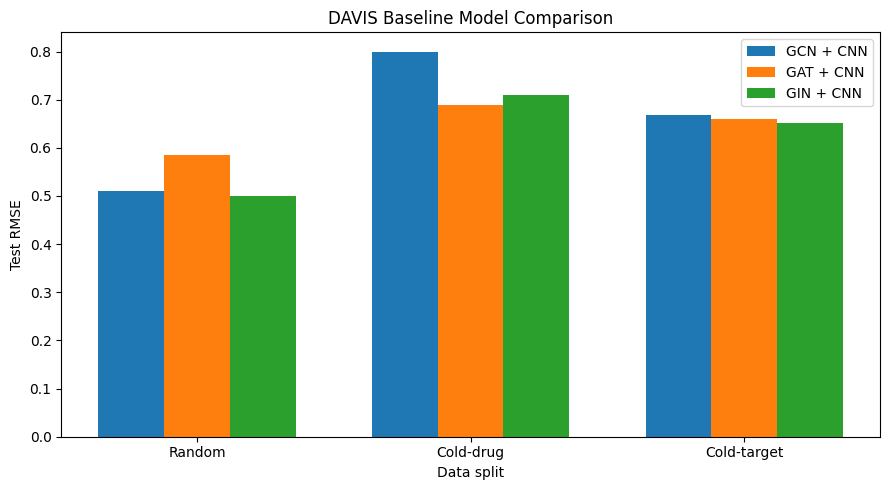

Saved: /content/final-msc-dissertation-drug-repurposing/results/figures/davis_baseline_rmse_comparison.png


In [10]:
split_order = [
    "random",
    "cold_drug",
    "cold_target",
]

model_order = [
    "GCN + CNN",
    "GAT + CNN",
    "GIN + CNN",
]

x = np.arange(
    len(split_order)
)

width = 0.24

plt.figure(figsize=(9, 5))

for index, model_name in enumerate(model_order):
    model_values = (
        davis_baseline_df[
            davis_baseline_df["model"]
            == model_name
        ]
        .set_index("split")
        .reindex(split_order)
        ["test_rmse"]
    )

    plt.bar(
        x + (index - 1) * width,
        model_values,
        width=width,
        label=model_name,
    )

plt.xticks(
    x,
    [
        "Random",
        "Cold-drug",
        "Cold-target",
    ],
)
plt.ylabel("Test RMSE")
plt.xlabel("Data split")
plt.title(
    "DAVIS Baseline Model Comparison"
)
plt.legend()
plt.tight_layout()

davis_baseline_figure = (
    FIGURES_DIR
    / "davis_baseline_rmse_comparison.png"
)

plt.savefig(
    davis_baseline_figure,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Saved:", davis_baseline_figure)

# Part D — KIBA baseline comparison

## 10. KIBA baseline results

KIBA is analysed separately because its affinity score is on a different scale from DAVIS pKd.

In [11]:
kiba_baseline_df = all_results_df[
    all_results_df["dataset"] == "KIBA"
].copy()

kiba_baseline_df = (
    kiba_baseline_df
    .sort_values(
        ["split", "test_rmse"]
    )
    .reset_index(drop=True)
)

display(
    kiba_baseline_df[
        [
            "model",
            "split",
            "test_rmse",
            "test_mae",
            "ci",
            "pearson",
            "best_epoch",
        ]
    ].round(4)
)

,model,split,test_rmse,test_mae,ci,pearson,best_epoch
0,GCN + CNN,cold_drug,0.5670,0.3739,0.7777,0.7241,129
1,GAT + CNN,cold_drug,0.5821,0.3741,0.7658,0.7124,138
2,GIN + CNN,cold_drug,0.6464,0.4296,0.7363,0.6189,31
3,GIN + CNN,cold_target,0.6609,0.4585,0.7180,0.6333,81
4,GCN + CNN,cold_target,0.6689,0.4607,0.7169,0.6221,74
5,GAT + CNN,cold_target,0.6712,0.4496,0.7234,0.6222,77
6,GIN + CNN,random,0.4732,0.2923,0.8410,0.8241,154
7,GCN + CNN,random,0.4777,0.2933,0.8380,0.8210,196
8,GAT + CNN,random,0.5300,0.3222,0.8208,0.7743,181


## 11. Rank KIBA baseline models within each split

In [12]:
kiba_baseline_ranked = (
    kiba_baseline_df.copy()
)

kiba_baseline_ranked["rmse_rank"] = (
    kiba_baseline_ranked
    .groupby("split")["test_rmse"]
    .rank(
        method="min",
        ascending=True,
    )
    .astype(int)
)

kiba_baseline_ranked = (
    kiba_baseline_ranked
    .sort_values(
        ["split", "rmse_rank"]
    )
    .reset_index(drop=True)
)

display(
    kiba_baseline_ranked[
        [
            "split",
            "rmse_rank",
            "model",
            "test_rmse",
            "ci",
            "pearson",
        ]
    ].round(4)
)

kiba_baseline_path = (
    COMPARISON_DIR
    / "kiba_baseline_comparison.csv"
)

kiba_baseline_ranked.to_csv(
    kiba_baseline_path,
    index=False,
)

print("Saved:", kiba_baseline_path)

,split,rmse_rank,model,test_rmse,ci,pearson
0,cold_drug,1,GCN + CNN,0.5670,0.7777,0.7241
1,cold_drug,2,GAT + CNN,0.5821,0.7658,0.7124
2,cold_drug,3,GIN + CNN,0.6464,0.7363,0.6189
3,cold_target,1,GIN + CNN,0.6609,0.7180,0.6333
4,cold_target,2,GCN + CNN,0.6689,0.7169,0.6221
5,cold_target,3,GAT + CNN,0.6712,0.7234,0.6222
6,random,1,GIN + CNN,0.4732,0.8410,0.8241
7,random,2,GCN + CNN,0.4777,0.8380,0.8210
8,random,3,GAT + CNN,0.5300,0.8208,0.7743


Saved: /content/final-msc-dissertation-drug-repurposing/results/metrics/comparisons/kiba_baseline_comparison.csv


## 12. KIBA baseline RMSE figure

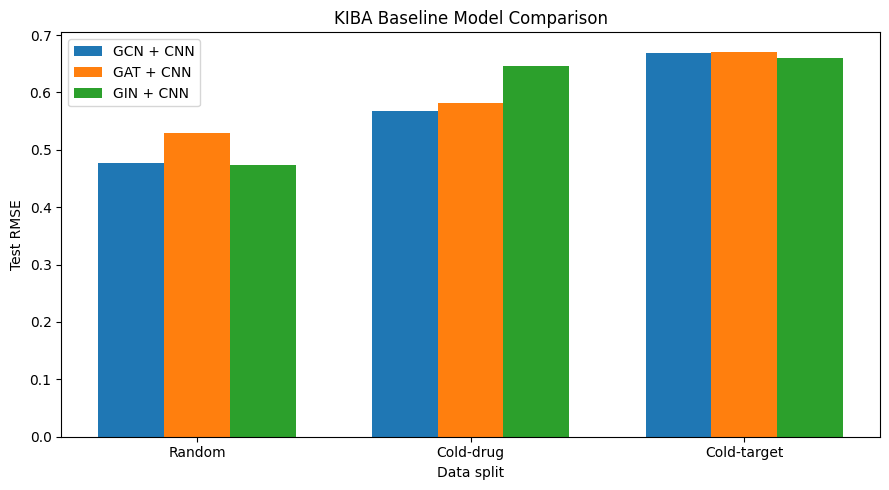

Saved: /content/final-msc-dissertation-drug-repurposing/results/figures/kiba_baseline_rmse_comparison.png


In [13]:
plt.figure(figsize=(9, 5))

for index, model_name in enumerate(model_order):
    model_values = (
        kiba_baseline_df[
            kiba_baseline_df["model"]
            == model_name
        ]
        .set_index("split")
        .reindex(split_order)
        ["test_rmse"]
    )

    plt.bar(
        x + (index - 1) * width,
        model_values,
        width=width,
        label=model_name,
    )

plt.xticks(
    x,
    [
        "Random",
        "Cold-drug",
        "Cold-target",
    ],
)
plt.ylabel("Test RMSE")
plt.xlabel("Data split")
plt.title(
    "KIBA Baseline Model Comparison"
)
plt.legend()
plt.tight_layout()

kiba_baseline_figure = (
    FIGURES_DIR
    / "kiba_baseline_rmse_comparison.png"
)

plt.savefig(
    kiba_baseline_figure,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Saved:", kiba_baseline_figure)

# Part E — DAVIS baseline versus advanced model

## 13. Combine all DAVIS models

The advanced architecture is compared only with the DAVIS baseline models because it was trained and evaluated on DAVIS using the same split definitions.

In [14]:
davis_all_models_df = all_results_df[
    all_results_df["dataset"] == "DAVIS"
].copy()

davis_all_models_df = (
    davis_all_models_df
    .sort_values(
        ["split", "test_rmse"]
    )
    .reset_index(drop=True)
)

display(
    davis_all_models_df[
        [
            "model",
            "split",
            "test_rmse",
            "test_mae",
            "ci",
            "pearson",
            "trainable_parameters",
        ]
    ].round(4)
)

,model,split,test_rmse,test_mae,ci,pearson,trainable_parameters
0,GAT + CNN,cold_drug,0.6893,0.4311,0.7639,0.5555,384897
1,GIN + CNN,cold_drug,0.7100,0.4459,0.7569,0.4450,433665
2,GCN + CNN,cold_drug,0.7999,0.4854,0.7736,0.5305,384129
3,GINE + frozen ESM-2 + CNN + cross-attention,cold_drug,0.9087,0.5493,0.8073,0.6107,1139463
4,GIN + CNN,cold_target,0.6519,0.3901,0.8344,0.7471,433665
5,GAT + CNN,cold_target,0.6592,0.3584,0.8404,0.7414,384897
6,GINE + frozen ESM-2 + CNN + cross-attention,cold_target,0.6633,0.3609,0.8297,0.7451,1139463
7,GCN + CNN,cold_target,0.6680,0.3899,0.8265,0.7555,384129
8,GIN + CNN,random,0.4996,0.2880,0.8785,0.8192,433665
9,GINE + frozen ESM-2 + CNN + cross-attention,random,0.5016,0.2509,0.8797,0.8313,1139463


## 14. Rank all DAVIS models by split

In [15]:
davis_all_ranked = (
    davis_all_models_df.copy()
)

davis_all_ranked["rmse_rank"] = (
    davis_all_ranked
    .groupby("split")["test_rmse"]
    .rank(
        method="min",
        ascending=True,
    )
    .astype(int)
)

davis_all_ranked = (
    davis_all_ranked
    .sort_values(
        ["split", "rmse_rank"]
    )
    .reset_index(drop=True)
)

display(
    davis_all_ranked[
        [
            "split",
            "rmse_rank",
            "model",
            "test_rmse",
            "test_mae",
            "ci",
            "pearson",
        ]
    ].round(4)
)

davis_all_path = (
    COMPARISON_DIR
    / "davis_all_models_comparison.csv"
)

davis_all_ranked.to_csv(
    davis_all_path,
    index=False,
)

print("Saved:", davis_all_path)

,split,rmse_rank,model,test_rmse,test_mae,ci,pearson
0,cold_drug,1,GAT + CNN,0.6893,0.4311,0.7639,0.5555
1,cold_drug,2,GIN + CNN,0.7100,0.4459,0.7569,0.4450
2,cold_drug,3,GCN + CNN,0.7999,0.4854,0.7736,0.5305
3,cold_drug,4,GINE + frozen ESM-2 + CNN + cross-attention,0.9087,0.5493,0.8073,0.6107
4,cold_target,1,GIN + CNN,0.6519,0.3901,0.8344,0.7471
5,cold_target,2,GAT + CNN,0.6592,0.3584,0.8404,0.7414
6,cold_target,3,GINE + frozen ESM-2 + CNN + cross-attention,0.6633,0.3609,0.8297,0.7451
7,cold_target,4,GCN + CNN,0.6680,0.3899,0.8265,0.7555
8,random,1,GIN + CNN,0.4996,0.2880,0.8785,0.8192
9,random,2,GINE + frozen ESM-2 + CNN + cross-attention,0.5016,0.2509,0.8797,0.8313


Saved: /content/final-msc-dissertation-drug-repurposing/results/metrics/comparisons/davis_all_models_comparison.csv


## 15. DAVIS RMSE comparison including the advanced model

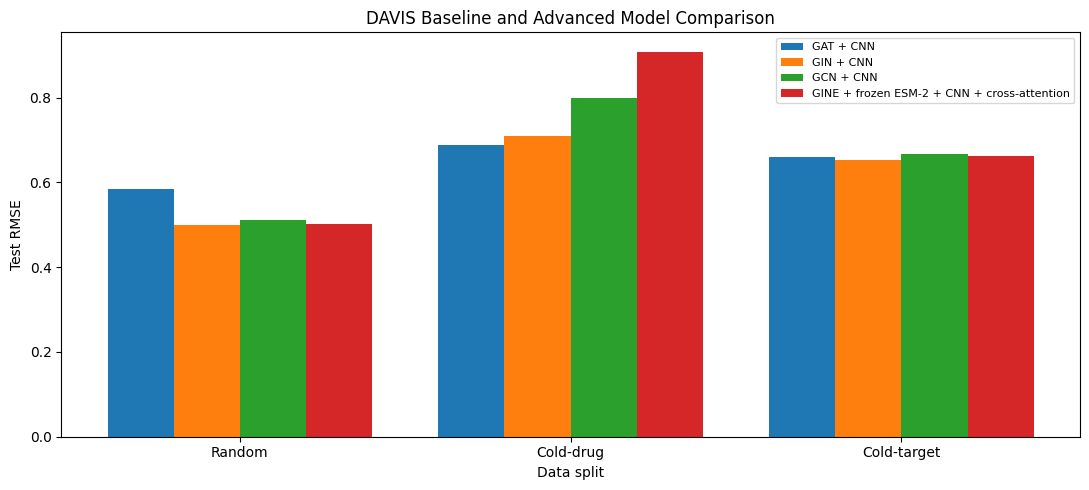

Saved: /content/final-msc-dissertation-drug-repurposing/results/figures/davis_all_models_rmse_comparison.png


In [16]:
davis_model_order = (
    davis_all_models_df["model"]
    .drop_duplicates()
    .tolist()
)

x_advanced = np.arange(
    len(split_order)
)

advanced_width = (
    0.8 / len(davis_model_order)
)

plt.figure(figsize=(11, 5))

for index, model_name in enumerate(
    davis_model_order
):
    model_values = (
        davis_all_models_df[
            davis_all_models_df["model"]
            == model_name
        ]
        .set_index("split")
        .reindex(split_order)
        ["test_rmse"]
    )

    offset = (
        index
        - (len(davis_model_order) - 1) / 2
    ) * advanced_width

    plt.bar(
        x_advanced + offset,
        model_values,
        width=advanced_width,
        label=model_name,
    )

plt.xticks(
    x_advanced,
    [
        "Random",
        "Cold-drug",
        "Cold-target",
    ],
)
plt.ylabel("Test RMSE")
plt.xlabel("Data split")
plt.title(
    "DAVIS Baseline and Advanced Model Comparison"
)
plt.legend(
    fontsize=8,
)
plt.tight_layout()

davis_all_figure = (
    FIGURES_DIR
    / "davis_all_models_rmse_comparison.png"
)

plt.savefig(
    davis_all_figure,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Saved:", davis_all_figure)

## 16. Compare Concordance Index on DAVIS

CI provides a complementary view to RMSE by measuring whether the model ranks stronger and weaker interactions in the correct order.

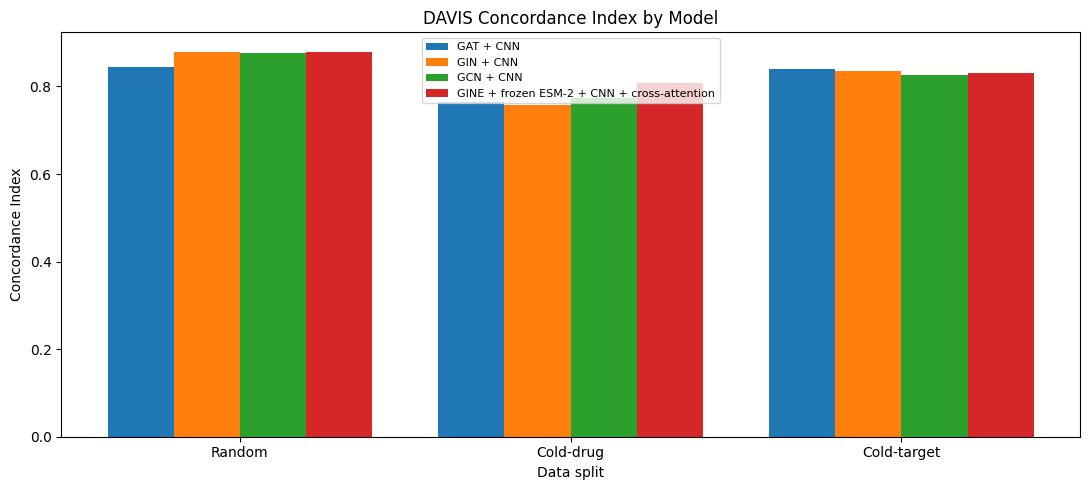

Saved: /content/final-msc-dissertation-drug-repurposing/results/figures/davis_all_models_ci_comparison.png


In [17]:
plt.figure(figsize=(11, 5))

for index, model_name in enumerate(
    davis_model_order
):
    model_values = (
        davis_all_models_df[
            davis_all_models_df["model"]
            == model_name
        ]
        .set_index("split")
        .reindex(split_order)
        ["ci"]
    )

    offset = (
        index
        - (len(davis_model_order) - 1) / 2
    ) * advanced_width

    plt.bar(
        x_advanced + offset,
        model_values,
        width=advanced_width,
        label=model_name,
    )

plt.xticks(
    x_advanced,
    [
        "Random",
        "Cold-drug",
        "Cold-target",
    ],
)
plt.ylabel("Concordance Index")
plt.xlabel("Data split")
plt.title(
    "DAVIS Concordance Index by Model"
)
plt.legend(
    fontsize=8,
)
plt.tight_layout()

davis_ci_figure = (
    FIGURES_DIR
    / "davis_all_models_ci_comparison.png"
)

plt.savefig(
    davis_ci_figure,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Saved:", davis_ci_figure)

# Part F — Best models and generalisation summary

## 17. Best model for each dataset and split

In [18]:
best_models_df = (
    all_results_df
    .sort_values("test_rmse")
    .groupby(
        ["dataset", "split"],
        as_index=False,
    )
    .first()
)

best_models_df = (
    best_models_df[
        [
            "dataset",
            "split",
            "model",
            "test_rmse",
            "test_mae",
            "ci",
            "pearson",
        ]
    ]
    .sort_values(
        ["dataset", "split"]
    )
    .reset_index(drop=True)
)

display(
    best_models_df.round(4)
)

best_models_path = (
    COMPARISON_DIR
    / "best_model_by_dataset_and_split.csv"
)

best_models_df.to_csv(
    best_models_path,
    index=False,
)

print("Saved:", best_models_path)

,dataset,split,model,test_rmse,test_mae,ci,pearson
0,DAVIS,cold_drug,GAT + CNN,0.6893,0.4311,0.7639,0.5555
1,DAVIS,cold_target,GIN + CNN,0.6519,0.3901,0.8344,0.7471
2,DAVIS,random,GIN + CNN,0.4996,0.2880,0.8785,0.8192
3,KIBA,cold_drug,GCN + CNN,0.5670,0.3739,0.7777,0.7241
4,KIBA,cold_target,GIN + CNN,0.6609,0.4585,0.7180,0.6333
5,KIBA,random,GIN + CNN,0.4732,0.2923,0.8410,0.8241


Saved: /content/final-msc-dissertation-drug-repurposing/results/metrics/comparisons/best_model_by_dataset_and_split.csv


## 18. Random-to-cold RMSE change

This table shows how much RMSE changes from the random split to each cold-start setting.

A positive value indicates worse performance under the cold-start setting.  
A negative value indicates lower RMSE than the random split for that particular experiment and should be interpreted together with the split composition rather than automatically as easier generalisation.

In [19]:
rmse_wide = (
    all_results_df
    .pivot_table(
        index=[
            "dataset",
            "model",
        ],
        columns="split",
        values="test_rmse",
    )
    .reset_index()
)

rmse_wide[
    "cold_drug_rmse_change"
] = (
    rmse_wide["cold_drug"]
    - rmse_wide["random"]
)

rmse_wide[
    "cold_target_rmse_change"
] = (
    rmse_wide["cold_target"]
    - rmse_wide["random"]
)

display(
    rmse_wide[
        [
            "dataset",
            "model",
            "random",
            "cold_drug",
            "cold_drug_rmse_change",
            "cold_target",
            "cold_target_rmse_change",
        ]
    ].round(4)
)

generalisation_path = (
    COMPARISON_DIR
    / "cold_start_rmse_change.csv"
)

rmse_wide.to_csv(
    generalisation_path,
    index=False,
)

print("Saved:", generalisation_path)

split,dataset,model,random,cold_drug,cold_drug_rmse_change,cold_target,cold_target_rmse_change
0,DAVIS,GAT + CNN,0.5849,0.6893,0.1044,0.6592,0.0743
1,DAVIS,GCN + CNN,0.5105,0.7999,0.2893,0.6680,0.1575
2,DAVIS,GIN + CNN,0.4996,0.7100,0.2105,0.6519,0.1523
3,DAVIS,GINE + frozen ESM-2 + CNN + cross-attention,0.5016,0.9087,0.4072,0.6633,0.1618
4,KIBA,GAT + CNN,0.5300,0.5821,0.0521,0.6712,0.1412
5,KIBA,GCN + CNN,0.4777,0.5670,0.0893,0.6689,0.1912
6,KIBA,GIN + CNN,0.4732,0.6464,0.1732,0.6609,0.1877


Saved: /content/final-msc-dissertation-drug-repurposing/results/metrics/comparisons/cold_start_rmse_change.csv


# Part G — Final comparison summary

## 19. Final result tables

In [20]:
print("DAVIS baseline ranking")
display(
    davis_baseline_ranked[
        [
            "split",
            "rmse_rank",
            "model",
            "test_rmse",
            "ci",
        ]
    ].round(4)
)

print()
print("KIBA baseline ranking")
display(
    kiba_baseline_ranked[
        [
            "split",
            "rmse_rank",
            "model",
            "test_rmse",
            "ci",
        ]
    ].round(4)
)

print()
print("DAVIS baseline + advanced ranking")
display(
    davis_all_ranked[
        [
            "split",
            "rmse_rank",
            "model",
            "test_rmse",
            "ci",
        ]
    ].round(4)
)

DAVIS baseline ranking


,split,rmse_rank,model,test_rmse,ci
0,cold_drug,1,GAT + CNN,0.6893,0.7639
1,cold_drug,2,GIN + CNN,0.7100,0.7569
2,cold_drug,3,GCN + CNN,0.7999,0.7736
3,cold_target,1,GIN + CNN,0.6519,0.8344
4,cold_target,2,GAT + CNN,0.6592,0.8404
5,cold_target,3,GCN + CNN,0.6680,0.8265
6,random,1,GIN + CNN,0.4996,0.8785
7,random,2,GCN + CNN,0.5105,0.8770
8,random,3,GAT + CNN,0.5849,0.8448



KIBA baseline ranking


,split,rmse_rank,model,test_rmse,ci
0,cold_drug,1,GCN + CNN,0.5670,0.7777
1,cold_drug,2,GAT + CNN,0.5821,0.7658
2,cold_drug,3,GIN + CNN,0.6464,0.7363
3,cold_target,1,GIN + CNN,0.6609,0.7180
4,cold_target,2,GCN + CNN,0.6689,0.7169
5,cold_target,3,GAT + CNN,0.6712,0.7234
6,random,1,GIN + CNN,0.4732,0.8410
7,random,2,GCN + CNN,0.4777,0.8380
8,random,3,GAT + CNN,0.5300,0.8208



DAVIS baseline + advanced ranking


,split,rmse_rank,model,test_rmse,ci
0,cold_drug,1,GAT + CNN,0.6893,0.7639
1,cold_drug,2,GIN + CNN,0.7100,0.7569
2,cold_drug,3,GCN + CNN,0.7999,0.7736
3,cold_drug,4,GINE + frozen ESM-2 + CNN + cross-attention,0.9087,0.8073
4,cold_target,1,GIN + CNN,0.6519,0.8344
5,cold_target,2,GAT + CNN,0.6592,0.8404
6,cold_target,3,GINE + frozen ESM-2 + CNN + cross-attention,0.6633,0.8297
7,cold_target,4,GCN + CNN,0.6680,0.8265
8,random,1,GIN + CNN,0.4996,0.8785
9,random,2,GINE + frozen ESM-2 + CNN + cross-attention,0.5016,0.8797


## 20. Automatic summary for dissertation notes

The statements printed below are descriptive summaries of the saved experimental results. They should still be interpreted in the dissertation together with the full metric tables and the characteristics of each split.

In [21]:
print("Best models by dataset and split")
print("-" * 70)

for _, row in best_models_df.iterrows():
    print(
        f'{row["dataset"]} | {row["split"]}: '
        f'{row["model"]} | '
        f'RMSE={row["test_rmse"]:.4f} | '
        f'CI={row["ci"]:.4f}'
    )

print()
print("DAVIS advanced-model position")
print("-" * 70)

advanced_rows = davis_all_ranked[
    davis_all_ranked["model"].str.contains(
        "GINE",
        case=False,
        na=False,
    )
]

display(
    advanced_rows[
        [
            "split",
            "rmse_rank",
            "test_rmse",
            "test_mae",
            "ci",
            "pearson",
        ]
    ].round(4)
)

Best models by dataset and split
----------------------------------------------------------------------
DAVIS | cold_drug: GAT + CNN | RMSE=0.6893 | CI=0.7639
DAVIS | cold_target: GIN + CNN | RMSE=0.6519 | CI=0.8344
DAVIS | random: GIN + CNN | RMSE=0.4996 | CI=0.8785
KIBA | cold_drug: GCN + CNN | RMSE=0.5670 | CI=0.7777
KIBA | cold_target: GIN + CNN | RMSE=0.6609 | CI=0.7180
KIBA | random: GIN + CNN | RMSE=0.4732 | CI=0.8410

DAVIS advanced-model position
----------------------------------------------------------------------


,split,rmse_rank,test_rmse,test_mae,ci,pearson
3,cold_drug,4,0.9087,0.5493,0.8073,0.6107
6,cold_target,3,0.6633,0.3609,0.8297,0.7451
9,random,2,0.5016,0.2509,0.8797,0.8313


## 21. Saved comparison outputs

In [22]:
saved_outputs = pd.DataFrame(
    {
        "output": [
            "All model results",
            "DAVIS baseline comparison",
            "KIBA baseline comparison",
            "DAVIS all-model comparison",
            "Best model by split",
            "Cold-start RMSE changes",
            "DAVIS baseline RMSE figure",
            "KIBA baseline RMSE figure",
            "DAVIS all-model RMSE figure",
            "DAVIS all-model CI figure",
        ],
        "path": [
            all_results_path,
            davis_baseline_path,
            kiba_baseline_path,
            davis_all_path,
            best_models_path,
            generalisation_path,
            davis_baseline_figure,
            kiba_baseline_figure,
            davis_all_figure,
            davis_ci_figure,
        ],
    }
)

display(saved_outputs)

,output,path
0,All model results,/content/final-msc-dissertation-drug-repurposi...
1,DAVIS baseline comparison,/content/final-msc-dissertation-drug-repurposi...
2,KIBA baseline comparison,/content/final-msc-dissertation-drug-repurposi...
3,DAVIS all-model comparison,/content/final-msc-dissertation-drug-repurposi...
4,Best model by split,/content/final-msc-dissertation-drug-repurposi...
5,Cold-start RMSE changes,/content/final-msc-dissertation-drug-repurposi...
6,DAVIS baseline RMSE figure,/content/final-msc-dissertation-drug-repurposi...
7,KIBA baseline RMSE figure,/content/final-msc-dissertation-drug-repurposi...
8,DAVIS all-model RMSE figure,/content/final-msc-dissertation-drug-repurposi...
9,DAVIS all-model CI figure,/content/final-msc-dissertation-drug-repurposi...


### Notebook completion

This notebook completes the quantitative comparison stage of the project.

The key methodological rules maintained here are:

- model rankings are calculated **within each dataset and split**;
- DAVIS and KIBA absolute RMSE values are not treated as directly comparable because their target scales differ;
- the advanced architecture is compared directly with the DAVIS baselines under the same random, cold-drug, and cold-target evaluation settings.

